In [ ]:
import os
import argparse
import datetime
import random
import math
import cv2
from typing import List, Dict, Tuple, Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.optim.lr_scheduler as lr_sched
from torch.utils.data import random_split, DataLoader
#from torch.utils.tensorboard import SummaryWriter
from lib.models.my_arcface import MyArcFace
from lib.utils_functions import seed_worker
import pandas as pd
from sklearn.model_selection import train_test_split
from tqdm import tqdm
'''
special modification for labeling in AIDY data
'''
#from lib.datasets.utils import get_train_and_val_datasets

from lib.datasets.gestalt_matcher_dataset import GestaltMatcherDataset
def __getitem__(self, i, to_augment=True):
    img = cv2.imread(os.path.join(self.imgs_dir, f"{self.targets.iloc[i]['image_id']}{self.img_postfix}.jpg"))
    #target_id = self.lookup_table.index(self.targets.iloc[i]['label'])

    df = pd.read_json("actual_swarm/swarm_study/lookup_table.json")
    df['label']=range(len(df))

    df2 = pd.read_csv("actual_swarm/swarm_study/image_to_class_correspondance.csv")
    df2["AIDY_class"] = df2["cohort"].map(df.set_index(0)['label'])
    target_id = df2[df2["image_number"] == self.targets.iloc[i]["image_id"]]["AIDY_class"].values[0]
    img = self.preprocess(img)
    return img, target_id

GestaltMatcherDataset.__getitem__ = __getitem__
def get_train_and_val_datasets(
        dataset,
        dataset_type,
        version,
        img_size,
        color_channels,
        base_dir,
        train_path,
        val_path,
        lookup_table=None,
        aspect_ratio=False,
        img_postfix='_crop_square'):

    if dataset == 'gmdb':
        dataset_train = GestaltMatcherDataset(
            in_channels=color_channels,
            img_postfix=img_postfix,
            target_size=img_size,
            imgs_dir=os.path.join(base_dir, "GestaltMatcherDB", version, "gmdb_align"),
            target_file_path= train_path, # os.path.join(base_dir, "GestaltMatcherDB", version, "gmdb_metadata",
            #                               f"gmdb_train_images_{version}.csv"),
            lookup_table=lookup_table,
            aspect_ratio=aspect_ratio)

        dataset_val = GestaltMatcherDataset(
            in_channels=color_channels,
            img_postfix=img_postfix,
            target_size=img_size,
            augment=False,
            imgs_dir=os.path.join(base_dir, "GestaltMatcherDB", version, "gmdb_align"),
            target_file_path=val_path, # os.path.join(base_dir, "GestaltMatcherDB", version, "gmdb_metadata",
                                        #   f"gmdb_val_images_{version}.csv"),
            lookup_table=(lookup_table if lookup_table else dataset_train.get_lookup_table()),
            aspect_ratio=aspect_ratio)

    # Unsupported dataset (or typo)
    else:
        print(f"Dataset: {dataset} unknown, exiting.")
        exit()

    print(f"Loaded dataset: {dataset}{'-' if dataset_type else ''}{dataset_type} (version {version}) with image size "
          f"{img_size}x{img_size} in {'gray' if color_channels == 1 else 'RGB'}, while {'' if aspect_ratio else 'not'} "
          f"retaining the aspect ratio.")
    return dataset_train, dataset_val

In [2]:
def parse_args():
    parser = argparse.ArgumentParser(description='PyTorch Modernized GestaltMatcher')

    # Run parameters
    parser.add_argument('--session', default= 1, type=int, dest='session',
                        help='session used to distinguish model tests.')
    parser.add_argument('--batch_size', type=int, default=128, metavar='BN',
                        help='input batch size for training (default: 280)')
    parser.add_argument('--epochs', type=int, default=1, metavar='E',
                        help='number of epochs to train (default: 500)')
    parser.add_argument('--lr', type=float, default=5e-3, metavar='LR',  # lr=1e-3
                        help='learning rate (default: 0.005)')
    parser.add_argument('--seed', type=int, default=11, metavar='S',
                        help='random seed (default: 11)')
    parser.add_argument('--no_cuda', action='store_true', default=False,
                        help='disables CUDA training')
    parser.add_argument('--log_interval', type=int, default=1000,
                        help='how many images (not batches) to wait before logging training status')
    parser.add_argument('--val_interval', type=int, default=10000,
                        help='how many images (not batches) to wait before validation is evaluated (and optimizer is stepped).')
    parser.add_argument('--use_tensorboard', action='store_true', default=False,
                        help='Use tensorboard for logging')

    # Model parameters
    parser.add_argument('--model_type', default='glint360k_r50', dest='model_type',
                        help='model backend to use')
    parser.add_argument('--in_channels', default=3, dest='in_channels', type=int,
                        help='number of color channels of the images used as input (default: 1)')
    parser.add_argument('--img_size', default=112, dest='img_size', type=int,
                        help='input image size of the model (default: 100)')
    parser.add_argument('--unfreeze', action='store_false', default=True, dest='freeze',
                        help='flag to set if you want to unfreeze the base model weights.')

    # Dataset parameters
    parser.add_argument('--dataset', default='gmdb', dest='dataset',
                        help='which dataset to use. (Options: "casia", "gmdb")')
    parser.add_argument('--dataset_type', default='', dest='dataset_type',
                        help='type of the dataset to use, e.g. normal (="") or augmented(="aug") (default="")')
    parser.add_argument('--dataset_version', default='v1.1.0', dest='dataset_version', type=str,
                        help='version of the dataset to use (default="v1.0.3")')
    parser.add_argument('--lookup_table', default='', dest='lookup_table_path',
                        help='lookup table path, use if you want to load path instead of generation a lookup table (default = "")')

    # File locations
    parser.add_argument('--data_dir', default='data', dest='data_dir',
                        help='Location of the data directory (not dataset). (default = home pc)')
    parser.add_argument('--weight_dir', default='saved_models', dest='weight_dir',
                        help='Location of the model weights directory. (default = "saved_models")')

    # running on my local machine means different path types, and num_workers
    parser.add_argument('--local', action='store_true', default=False,
                        help='Running on local machine, fewer num_workers')

    #
    parser.add_argument('--paper_model', default='a', dest='paper_model', type=str,
                        help='Use when reproducing paper models a) r50-mix, or b) r100')

    return parser.parse_known_args()


args, unknown = parse_args()


use_cuda = not args.no_cuda and torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
print(f"Using {'GPU.' if use_cuda else 'CPU, as was explicitly requested, or as GPU is not available.'}")

# Seed everything
np.random.seed(args.seed)
torch.manual_seed(args.seed)
random.seed(args.seed)

# When using GPU we need to set extra seeds
if use_cuda:
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.cuda.manual_seed_all(args.seed)
    torch.cuda.manual_seed(args.seed)
# torch.set_deterministic(True)

# If we want to reproduce paper results, by giving command-line argument `args.paper_model` == 'a' or 'b',
# we replace some other parameters
f_wd = c_wd = lr = c_lr = -1
if args.paper_model == 'a':    # r50 mix
    args.model_type = 'glint360k_r50'
    args.batch_size = 64
    f_wd = 5e-5
    c_wd = 5e-4
    lr = 5e-4
    c_lr = 1e-3
elif args.paper_model == 'b':  # r100
    args.model_type = 'glint360k_r100'
    args.batch_size = 128
    f_wd = 0.
    c_wd = 5e-4
    lr = 1e-3
    c_lr = 1e-3

# Dataset and dataloaders
kwargs = {}
if use_cuda:
    kwargs.update({'num_workers': (0 if args.local else 16), 'pin_memory': True})

dataset_train = dataset_val = None
lookup_table = None
distr = None
args.val_bs = 1

# Create and get the training and validation datasets
dataset_train, dataset_val = get_train_and_val_datasets(args.dataset, args.dataset_type, args.dataset_version,
                                                        args.img_size, args.in_channels, args.data_dir,
                                                        train_path=os.path.join(args.data_dir, "GestaltMatcherDB", 
                                                                                args.dataset_version,"gmdb_metadata",f"gmdb_train_images_{args.dataset_version}.csv"),
                                                        val_path=os.path.join(args.data_dir, "GestaltMatcherDB", 
                                                                                args.dataset_version,"gmdb_metadata",f"gmdb_val_images_{args.dataset_version}.csv"),
                                                        img_postfix='_aligned')
    
        # Get the number of classes from the dataset
args.num_classes = dataset_train.get_num_classes()

# Create dataloaders
train_loader = torch.utils.data.DataLoader(dataset_train, **kwargs, shuffle=True, batch_size=args.batch_size,
                                            worker_init_fn=seed_worker, drop_last=True)
val_loader = torch.utils.data.DataLoader(dataset_val, pin_memory=True, num_workers=12, shuffle=False,
                                            drop_last=False,worker_init_fn=seed_worker,batch_size=args.val_bs)

# Attempt to deal with data imbalance: inverse frequency divided by lowest frequency class (0.5 < class_weight <= 1)
if distr is not None:
    args.ce_weights = (torch.tensor([(sum(distr) / freq) / (sum(distr) / min(distr)) for freq in distr]).float()
                        .to(device)) * 0.5 + 0.5
else:
    args.ce_weights = None

# Set log intervals
args.log_interval = args.log_interval // args.batch_size
args.val_interval = args.val_interval // args.batch_size

use_cuda = not args.no_cuda and torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
print(f"Using {'GPU.' if use_cuda else 'CPU, as was explicitly requested, or as GPU is not available.'}")

# Try and get the dataset distribution and lookup table
try:
    distr = dataset_train.get_distribution()
    print(f"Training dataset size: {sum(distr)}, with {len(distr)} classes and distribution: {distr}")
    print(f"Validation dataset size: {sum(dataset_val.get_distribution())}, "
            f"with distribution: {dataset_val.get_distribution()}")

    lookup_table = dataset_train.get_lookup_table()
except:
    print("An error occurred while getting the dataset distribution and lookup table. Likely the dataset does not "
            "have an implementation for these functions.")
    



Using GPU.
no look up table found
look up table found
Loaded dataset: gmdb (version v1.1.0) with image size 112x112 in RGB, while not retaining the aspect ratio.
Using GPU.
Training dataset size: 7787, with 275 classes and distribution: [361, 241, 224, 171, 168, 147, 144, 132, 131, 119, 111, 96, 93, 93, 84, 75, 75, 74, 73, 72, 71, 69, 67, 63, 63, 62, 61, 56, 54, 54, 54, 51, 51, 50, 49, 47, 47, 47, 45, 45, 44, 44, 43, 42, 42, 42, 42, 42, 42, 40, 39, 39, 38, 38, 37, 36, 36, 36, 35, 35, 35, 34, 33, 33, 31, 31, 31, 31, 30, 30, 30, 30, 29, 29, 29, 28, 28, 28, 28, 27, 27, 27, 27, 27, 26, 26, 26, 26, 26, 26, 26, 25, 25, 24, 24, 24, 24, 24, 24, 23, 23, 23, 23, 23, 23, 22, 22, 22, 21, 21, 21, 21, 21, 21, 21, 21, 21, 20, 20, 20, 20, 19, 19, 19, 19, 19, 19, 19, 18, 18, 18, 18, 18, 18, 18, 17, 17, 17, 17, 17, 17, 17, 17, 17, 16, 16, 16, 16, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 14, 14, 14, 13, 13, 13, 13, 13, 13, 13, 12, 12, 12, 12, 12, 12, 12, 12, 12, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11,

In [ ]:
import pandas as pd
import torch
import os
use_cuda = torch.cuda.is_available() 
device = torch.device("cuda" if use_cuda else "cpu")

if use_cuda:
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

data = os.listdir('data/GestaltMatcherDB/v1.1.0/gmdb_align')
img_meta = pd.read_csv('data/GestaltMatcherDB/v1.1.0/gmdb_metadata/image_metadata_v1.1.0.tsv', sep='\t')
img_meta = img_meta[['image_id', 'filename', 'internal_syndrome_id', 'age_year','gender','ethnicity']]

training = pd.read_csv('data/GestaltMatcherDB/v1.1.0/gmdb_metadata/gmdb_train_images_v1.1.0.csv')
training = training.merge(
    img_meta[['image_id', 'age_year','gender','ethnicity']],
    on='image_id',
    how='left'   # keeps all rows in training
)
validation = pd.read_csv('data/GestaltMatcherDB/v1.1.0/gmdb_metadata/gmdb_val_images_v1.1.0.csv')
validation = validation.merge(
    img_meta[['image_id', 'age_year','gender','ethnicity']],
    on='image_id',
    how='left'   
)
test = pd.read_csv('data/GestaltMatcherDB/v1.1.0/gmdb_metadata/gmdb_test_images_v1.1.0.csv')
test = test.merge(
    img_meta[['image_id', 'age_year','gender','ethnicity']],
    on='image_id',
    how='left'   
)

In [ ]:
syndrome_name=pd.read_csv('data/GestaltMatcherDB/v1.1.0/gmdb_metadata/gmdb_syndromes_v1.1.0.tsv', sep='\t')
interesting_syndromes = ['Noonan syndrome','Coffin-Siris syndrome','CROUZON SYNDROME','Treacher Collins syndrome',
'CHROMOSOME 22q11.2 DELETION SYNDROME, DISTAL','WILLIAMS-BEUREN SYNDROME; WBS','SMITH-LEMLI-OPITZ SYNDROME; SLOS','Kabuki syndrome','ANGELMAN SYNDROME; AS','COSTELLO SYNDROME; CSTLO',
'LEOPARD syndrome','Cardiofaciocutaneous syndrome','PFEIFFER SYNDROME','APERT SYNDROME','MUENKE SYNDROME; MNKES','Cole-Carpenter syndrome','Stickler syndrome',
'SAETHRE-CHOTZEN SYNDROME; SCS','ACROFACIAL DYSOSTOSIS 1, NAGER TYPE; AFD1','CRANIOFRONTONASAL SYNDROME; CFNS', 'Orofaciodigital syndrome','CLEFT PALATE, CARDIAC DEFECTS, AND MENTAL RETARDATION; CPCMR',
'Silver-Russell syndrome','MCCUNE-ALBRIGHT SYNDROME; MAS','MARSHALL SYNDROME; MRSHS','MARSHALL-SMITH SYNDROME; MRSHSS','SMITH-LEMLI-OPITZ SYNDROME; SLOS','CHARGE SYNDROME',
'Trichorhinophalangeal syndrome','Joubert syndrome','Baraitser-Winter syndrome','Alagille syndrome','OGDEN SYNDROME; OGDNS','Robinow syndrome']
interesting_syndromes_short_name = ['Noonan','Coffin-Siris','Crouzon','Treacher-Collins',
'22q11.2','Williams-Beuren','Smith-Lemli-Opitz','Kabuki','Angelman','Costello',
'Leopard','Cardiofaciocutaneous','Pfeiffer','Apert','Muenke','Cole-Carpenter','Stickler',
'Saethre-Chotzen','Acrofacial-Nager','Cranio-Fronto-Nasal','Orofacial','Cleft Palate','Silver-Russell','Albright','Marshall','Marshall-Smith','Smith-Lemli-Opitz','Charge',
'Tricho-rhino-phalangeal','Joubert','Baraitser-Winter','Alagille','Ogden','Robinow']
# Preprocessing used for ArcFace input image inference
def preprocess(img, img_size=112, gray=False, flip=False):
    img = cv2.resize(img, (img_size, img_size))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    if gray:
        # desired number of channels is 1, so we convert to gray
        img = A.to_gray(img)
    #else: color

    if flip:
        img = A.hflip(img)
    #else: normal

    # normalize pixel values in range [-1,1]
    img = np.transpose(img, (2, 0, 1))
    img = torch.from_numpy(img).unsqueeze(0).float()
    img.div_(255).sub_(0.5).div_(0.5)
    return img

gmdb_data = pd.concat([training, validation, test], ignore_index=True)
# gmdb_data = pd.concat( [validation, test], ignore_index=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GM_AI_label = pd.read_csv('actual_swarm/swarm_study/gmdb_aidy_label_mapping.csv')

# central_model= torch.load('actual_swarm/swarm2/s1_glint360k_r100_512d_gmdb__v1.1.0_bs64_size112_channels3_last_model.pth',
#                 map_location=device).to(device)
central_model= torch.load('actual_swarm/swarm_study/GMDB_org_central_model/s2_glint360k_r100_512d_gmdb__v1.1.0_bs128_size112_channels3_last_model.pth',
                map_location=device).to(device)
swarm_model= torch.load("actual_swarm/swarm_study/s1_glint360k_r100_512d_gmdb_aidy__v1.1.0_bs128_size112_channels3_swarm_model_merged.pth",
                  map_location=device).to(device)
central_model.eval().to(device)
swarm_model.eval().to(device)



import pandas as pd
import re

GM_AI_label = pd.read_csv(
    "actual_swarm/swarm_study/gmdb_aidy_label_mapping.csv"
)

syndrome_name = pd.read_csv(
    "data/GestaltMatcherDB/v1.1.0/gmdb_metadata/gmdb_syndromes_v1.1.0.tsv",
    sep="\t"
)

interesting = (
    GM_AI_label.merge(
        syndrome_name[['syndrome_id', 'syndrome_name']],
        left_on='GMDB_label',
        right_on='syndrome_id',
        how='left'
    )
)

pattern = '|'.join(re.escape(s.lower()) for s in interesting_syndromes)

interesting = interesting[
    interesting['syndrome_name'].str.lower().str.contains(pattern, na=False)
].copy()

def get_short_name(full_name):
    full_lower = full_name.lower()
    for long_name, short_name in zip(
        interesting_syndromes,
        interesting_syndromes_short_name
    ):
        if long_name.lower() in full_lower:
            return short_name
    return full_name

interesting["short_name"] = interesting["syndrome_name"].apply(get_short_name)

interesting = interesting[
    ["AIDY_GMDB_label",
        "GMDB_label",
        "syndrome_name",
        "short_name"
    ]
].drop_duplicates().reset_index(drop=True)

interesting=interesting.drop(27) # noonan-like symdrome is also labelled as Noonan, so removing 
interesting

,AIDY_GMDB_label,GMDB_label,syndrome_name,short_name
0,264,1,WILLIAMS-BEUREN SYNDROME; WBS,Williams-Beuren
1,224,2,Noonan syndrome,Noonan
2,113,3,Kabuki syndrome,Kabuki
3,83,4,Coffin-Siris syndrome,Coffin-Siris
4,240,6,ANGELMAN SYNDROME; AS,Angelman
5,132,11,OGDEN SYNDROME; OGDNS,Ogden
6,251,12,SMITH-LEMLI-OPITZ SYNDROME; SLOS,Smith-Lemli-Opitz
7,195,15,Alagille syndrome,Alagille
8,139,20,Baraitser-Winter syndrome,Baraitser-Winter
9,262,21,Treacher Collins syndrome,Treacher-Collins


100%|██████████| 10980/10980 [08:06<00:00, 22.56it/s] 



CENTRAL MODEL
Silhouette: 0.1625249
Davies-Bouldin: 2.6585533269453987
Calinski-Harabasz: 29.280230574113432

SWARM MODEL
Silhouette: 0.10033115
Davies-Bouldin: 3.106884442148511
Calinski-Harabasz: 22.244389493473257


/home/bandyopadhyaya/GestaltMatcher_latest/env_gm/lib64/python3.6/site-packages/umap/umap_.py:1953: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism."


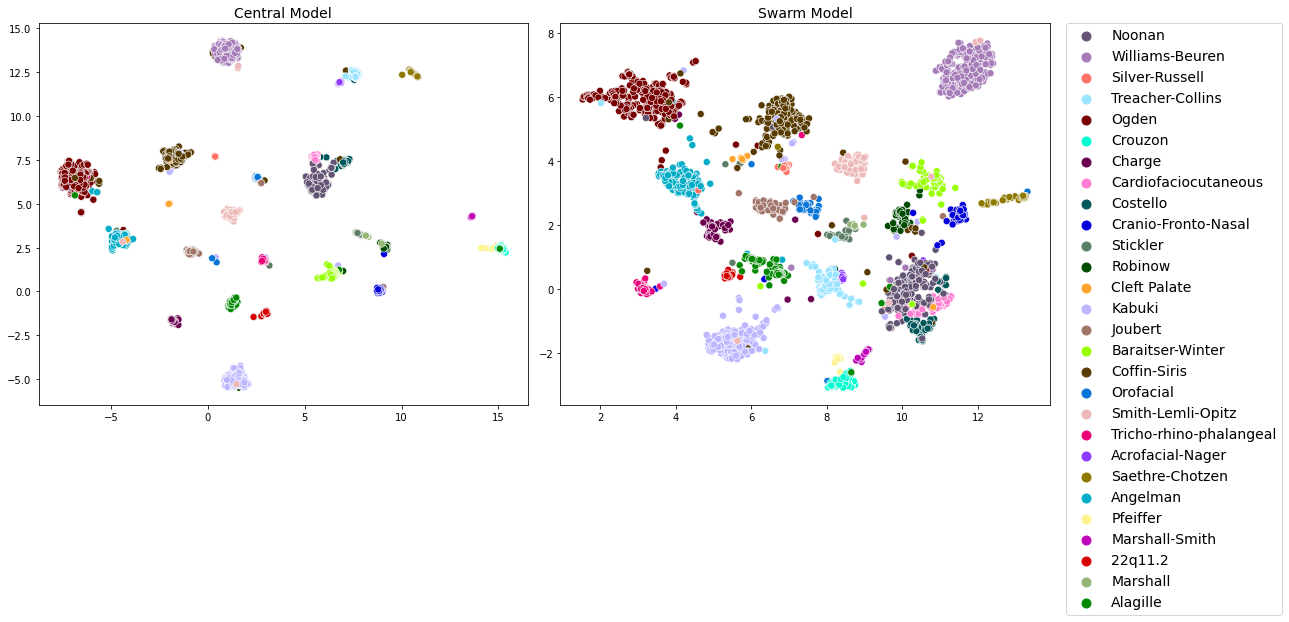

In [ ]:
import os
import re
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)
import umap.umap_ as umap


pattern = '|'.join([re.escape(s.lower()) for s in interesting_syndromes])

interesting_df = syndrome_name[
    syndrome_name['syndrome_name'].str.lower().str.contains(pattern, na=False)
].copy()

def get_short_name(full_name):
    full_lower = full_name.lower()
    for long_name, short_name in zip(
        interesting_syndromes,
        interesting_syndromes_short_name,
    ):
        if long_name.lower() in full_lower:
            return short_name
    return full_name

interesting_df["short_name"] = interesting_df["syndrome_name"].apply(get_short_name)

id_to_short = dict(
    zip(
        interesting_df["syndrome_id"],
        interesting_df["short_name"]
    )
)

central_embeddings = []
swarm_embeddings = []

labels = []
names = []

central_model.eval()
swarm_model.eval()

with torch.no_grad():

    for img_path in tqdm(data):

        img_id = int(img_path.split("_")[0])

        row = gmdb_data.loc[gmdb_data.image_id == img_id]

        if len(row) == 0:
            continue

        gmdb_label = row.iloc[0][gmdb_data.columns[2]]

        if gmdb_label not in id_to_short:
            continue

        img = cv2.imread(
            os.path.join(
                "data/GestaltMatcherDB/v1.1.0/gmdb_align",
                img_path)
        )

        img = preprocess(img).to(device)
        _, emb_c = central_model(img)
        _, emb_s = swarm_model(img)

        emb_c = emb_c.squeeze().cpu().numpy()
        emb_s = emb_s.squeeze().cpu().numpy()

        central_embeddings.append(emb_c)
        swarm_embeddings.append(emb_s)

        labels.append(gmdb_label)
        names.append(id_to_short[gmdb_label])

central_embeddings = np.vstack(central_embeddings)
swarm_embeddings = np.vstack(swarm_embeddings)

labels = np.array(labels)
names = np.array(names)

central_embeddings = normalize(central_embeddings)

swarm_embeddings = normalize(swarm_embeddings)

print("\nCENTRAL MODEL")
print("Silhouette:",silhouette_score(central_embeddings,labels,metric="cosine"))

print("Davies-Bouldin:",davies_bouldin_score(central_embeddings,labels))

print("Calinski-Harabasz:",calinski_harabasz_score(central_embeddings,labels))

print("\nSWARM MODEL")

print("Silhouette:",silhouette_score(swarm_embeddings,labels,metric="cosine"))

print("Davies-Bouldin:",davies_bouldin_score(swarm_embeddings,labels))

print("Calinski-Harabasz:",calinski_harabasz_score(swarm_embeddings,labels))

# UMAP
reducer = umap.UMAP(metric="cosine",random_state=42)

central_2d = reducer.fit_transform(central_embeddings)
swarm_2d = reducer.fit_transform(swarm_embeddings)




# Plot
import colorcet as cc

labels = np.unique(names)

palette = cc.glasbey[:len(labels)]
# palette = (
#     sns.color_palette("tab20") +
#     sns.color_palette("Set3") +
#     sns.color_palette("Paired")
# )

# palette = palette[:len(np.unique(names))]

palette_dict = dict(zip(labels, palette))



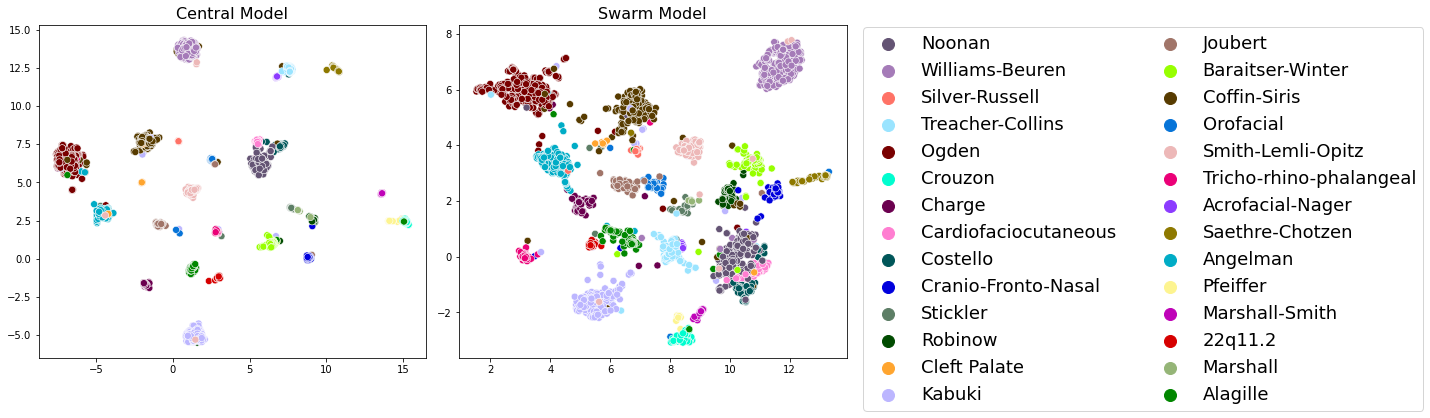

In [102]:

fig, ax = plt.subplots(1,2,figsize=(20,6))

sns.scatterplot(
    x=central_2d[:,0],
    y=central_2d[:,1],
    hue=names,
    palette=palette_dict,
    s=50,
    ax=ax[0]
)

ax[0].set_title("Central Model",fontsize=16)
# ax[0].legend(bbox_to_anchor=(1.02,1.02),loc="upper left",fontsize=12,markerscale=1.5, ncol=2)

sns.scatterplot(
    x=swarm_2d[:,0],
    y=swarm_2d[:,1],
    hue=names,
    palette=palette_dict,#'tab20',
    s=50,
    ax=ax[1]
)

ax[1].set_title("Swarm Model",fontsize=16)

handles, labels_plot = ax[1].get_legend_handles_labels()

ax[0].legend([], [], frameon=False)
# ax[1].legend([], [], frameon=False)
ax[1].legend(bbox_to_anchor=(1.02,1.02),loc="upper left",fontsize=18,markerscale=2, ncol=2)

plt.tight_layout()
plt.show()


In [63]:
[[id_to_name[swarm_df.iloc[i,0]],swarm_df.iloc[i,1]] for i in range(len(swarm_df)) if i != 27 ]

[['Williams-Beuren', 0.4720902740955353],
 ['Noonan', 0.5036311149597168],
 ['Kabuki', 0.42293184995651245],
 ['Coffin-Siris', 0.38400331139564514],
 ['Angelman', 0.46094703674316406],
 ['Ogden', 0.4918227195739746],
 ['Smith-Lemli-Opitz', 0.4748692512512207],
 ['Alagille', 0.45277440547943115],
 ['Baraitser-Winter', 0.4280311167240143],
 ['Treacher-Collins', 0.43253210186958313],
 ['Tricho-rhino-phalangeal', 0.536430835723877],
 ['Charge', 0.44797763228416443],
 ['Cardiofaciocutaneous', 0.6035000085830688],
 ['Crouzon', 0.6601102352142334],
 ['Joubert', 0.4609109163284302],
 ['Cranio-Fronto-Nasal', 0.5282865762710571],
 ['Robinow', 0.5190999507904053],
 ['Saethre-Chotzen', 0.515758752822876],
 ['Costello', 0.5070233345031738],
 ['22q11.2', 0.6272348165512085],
 ['Orofacial', 0.4407680034637451],
 ['Stickler', 0.5034995079040527],
 ['Marshall-Smith', 0.5786435008049011],
 ['Acrofacial-Nager', 0.585333526134491],
 ['Cleft Palate', 0.5635934472084045],
 ['Pfeiffer', 0.5722197890281677],


In [43]:
id_to_name

{1: 'Williams-Beuren',
 2: 'Noonan',
 3: 'Kabuki',
 4: 'Coffin-Siris',
 6: 'Angelman',
 11: 'Ogden',
 12: 'Smith-Lemli-Opitz',
 15: 'Alagille',
 20: 'Baraitser-Winter',
 21: 'Treacher-Collins',
 26: 'Tricho-rhino-phalangeal',
 29: 'Charge',
 31: 'Cardiofaciocutaneous',
 33: 'Crouzon',
 36: 'Joubert',
 40: 'Cranio-Fronto-Nasal',
 43: 'Robinow',
 49: 'Saethre-Chotzen',
 50: 'Costello',
 61: '22q11.2',
 82: 'Orofacial',
 98: 'Stickler',
 114: 'Marshall-Smith',
 127: 'Acrofacial-Nager',
 157: 'Cleft Palate',
 161: 'Pfeiffer',
 197: 'Marshall',
 273: 'Silver-Russell'}

In [42]:
central_df

,Disease,Similarity,Model
0,1,0.554891,Central
1,2,0.520503,Central
2,3,0.515933,Central
3,4,0.466167,Central
4,6,0.523818,Central
5,11,0.512997,Central
6,12,0.511800,Central
7,15,0.514782,Central
8,20,0.498314,Central
9,21,0.565926,Central


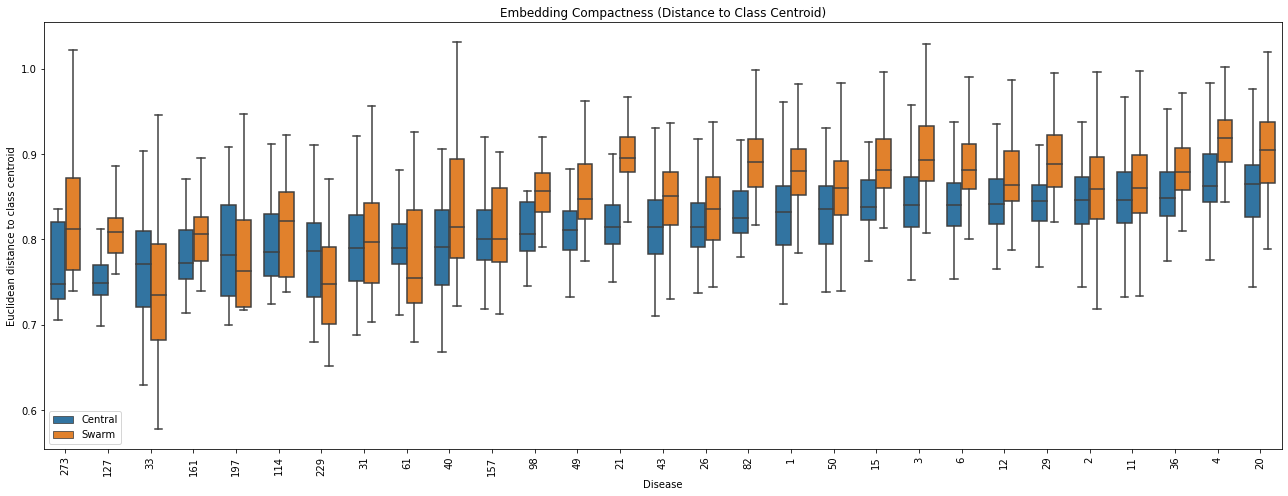

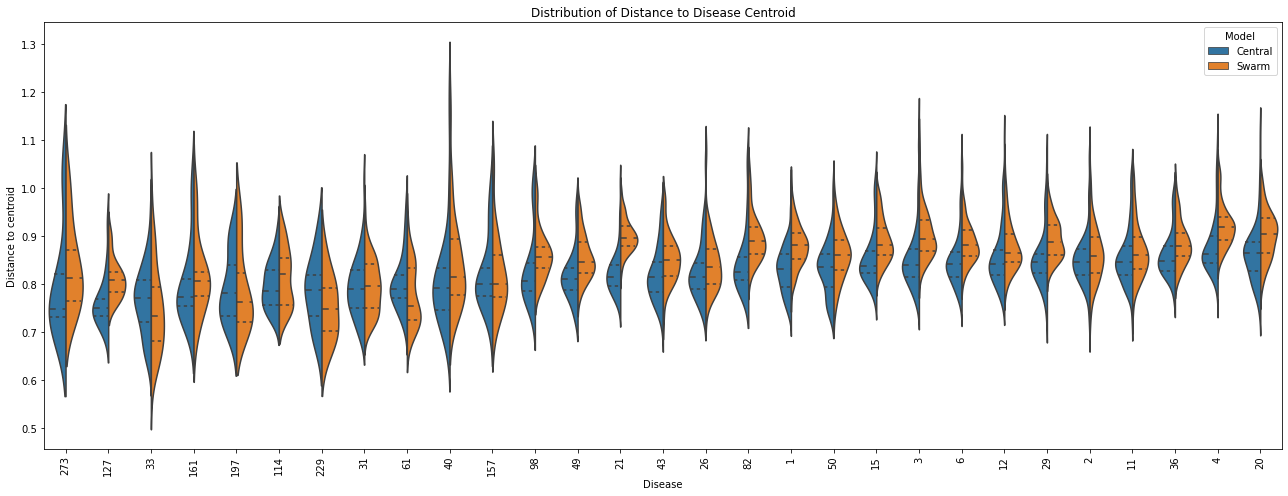

In [ ]:
# 5. Distance to centroid boxplot 
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

records = []

labels = np.array(labels)      # disease names (strings)

for disease in np.unique(labels):

    mask = labels == disease

    if np.sum(mask) < 3:
        continue

    emb = central_embeddings[mask]
    centroid = emb.mean(axis=0)
    dist = np.linalg.norm(emb - centroid, axis=1)

    for d in dist:
        records.append({
            "Disease": disease,
            "Distance": d,
            "Model": "Central"
        })

    emb = swarm_embeddings[mask]
    centroid = emb.mean(axis=0)
    dist = np.linalg.norm(emb - centroid, axis=1)

    for d in dist:
        records.append({
            "Disease": disease,
            "Distance": d,
            "Model": "Swarm"
        })


df = pd.DataFrame(records)

order = (
    df[df.Model=="Central"]
      .groupby("Disease")["Distance"]
      .median()
      .sort_values()
      .index
)


plt.figure(figsize=(18,7))

sns.boxplot(data=df,x="Disease",y="Distance",
    hue="Model",order=order,width=0.7,showfliers=False)

plt.xticks(rotation=90)

plt.ylabel("Euclidean distance to class centroid")
plt.xlabel("Disease")
plt.title("Embedding Compactness (Distance to Class Centroid)")

plt.legend(title="")

plt.tight_layout()
plt.show()

plt.figure(figsize=(18,7))

sns.violinplot(data=df,x="Disease",y="Distance",
    hue="Model",split=True,inner="quartile",order=order)

plt.xticks(rotation=90)

plt.ylabel("Distance to centroid")
plt.title("Distribution of Distance to Disease Centroid")

plt.tight_layout()
plt.show()

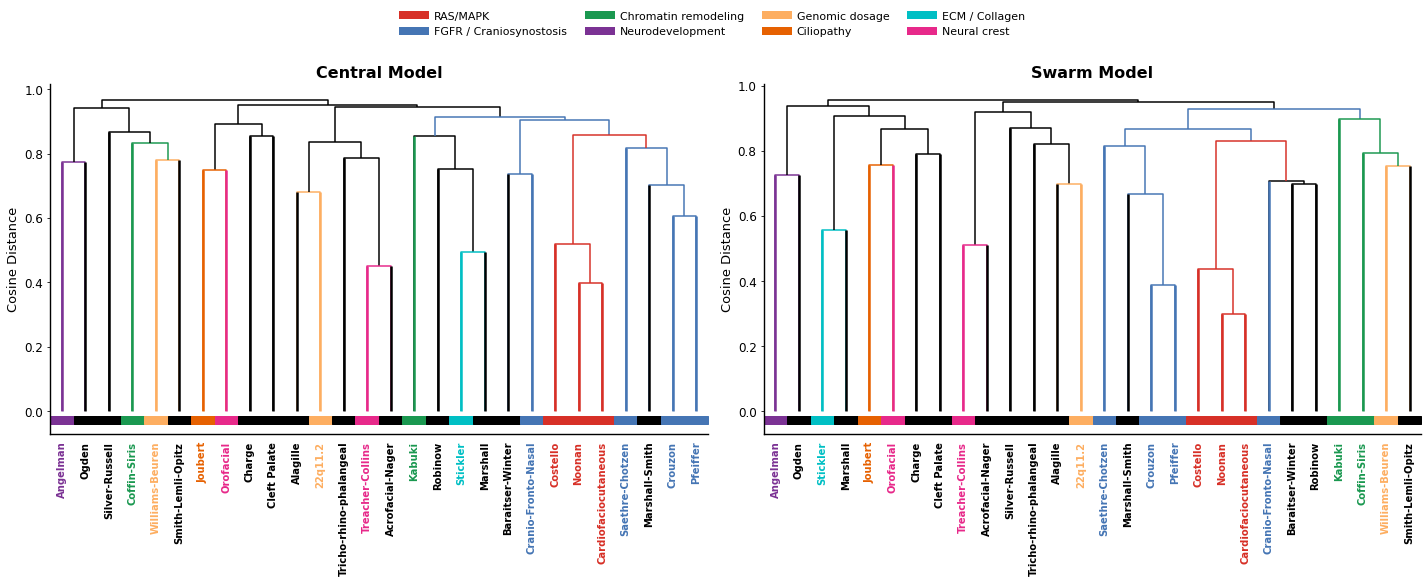

In [ ]:
# enhanced dendogram
from scipy.cluster.hierarchy import dendrogram
from matplotlib.lines import Line2D
import matplotlib.patches as patches
import matplotlib.pyplot as plt
from collections import Counter
import numpy as np


# ============================================================
# Disease family colors
# ============================================================

family_palette = {
    "RAS/MAPK": "#d73027",
    "FGFR / Craniosynostosis": "#4575b4",
    "Chromatin remodeling": "#1a9850",
    "Neurodevelopment": "#7b3294",
    "Genomic dosage": "#fdae61",
    "Ciliopathy": "#e66101",
    "ECM / Collagen": "#00bfc4",
    "Neural crest": "#e7298a",
    "Unknown": "black"
}


# ============================================================
# Disease -> family mapping
# ============================================================

disease_family = {
    "Noonan": "RAS/MAPK",
    "Cardiofaciocutaneous": "RAS/MAPK",
    "Costello": "RAS/MAPK",
    "Leopard": "RAS/MAPK",

    "Crouzon": "FGFR / Craniosynostosis",
    "Pfeiffer": "FGFR / Craniosynostosis",
    "Apert": "FGFR / Craniosynostosis",
    "Muenke": "FGFR / Craniosynostosis",
    "Saethre-Chotzen": "FGFR / Craniosynostosis",
    "Cranio-Fronto-Nasal": "FGFR / Craniosynostosis",

    "Kabuki": "Chromatin remodeling",
    "Coffin-Siris": "Chromatin remodeling",

    "Angelman": "Neurodevelopment",

    "22q11.2": "Genomic dosage",
    "Williams-Beuren": "Genomic dosage",

    "Joubert": "Ciliopathy",

    "Stickler": "ECM / Collagen",

    "Treacher-Collins": "Neural crest",
    "Orofacial": "Neural crest"
}


# ============================================================
# Branch colors
# ============================================================

def create_branch_colors(Z, labels):

    n = len(labels)

    family_counts_at = {
        i: Counter([disease_family.get(labels[i], "Unknown")])
        for i in range(n)
    }

    branch_colors = {}
    family_order = list(family_palette.keys())

    for i, (i1, i2, dist, cnt) in enumerate(Z):
        i1, i2 = int(i1), int(i2)
        new_id = n + i

        merged_counts = family_counts_at[i1] + family_counts_at[i2]
        family_counts_at[new_id] = merged_counts

        max_count = max(merged_counts.values())
        candidates = [f for f, c in merged_counts.items() if c == max_count]

        majority_family = (
            candidates[0] if len(candidates) == 1
            else next(f for f in family_order if f in candidates)
        )

        branch_colors[new_id] = family_palette.get(majority_family, "black")

    return branch_colors


def leaf_first_merge_heights(Z, n):
   
    heights = {}
    for i1, i2, dist, cnt in Z:
        i1, i2 = int(i1), int(i2)
        if i1 < n and i1 not in heights:
            heights[i1] = dist
        if i2 < n and i2 not in heights:
            heights[i2] = dist
    return heights


def plot_pub_dendrogram(ax, Z, labels, title):

    n = len(labels)
    branch_colors = create_branch_colors(Z, labels)
    stem_heights = leaf_first_merge_heights(Z, n)

    dendro = dendrogram(
        Z,
        labels=labels,
        leaf_rotation=90,
        leaf_font_size=10,
        link_color_func=lambda x: branch_colors.get(x, "black"),
        ax=ax
    )

  
    for line in ax.get_lines():
        line.set_linewidth(2.5)

 
    displayed_leaves = dendro["leaves"]  # original indices, left->right
    for pos, orig_idx in enumerate(displayed_leaves):
        disease = labels[orig_idx]
        family = disease_family.get(disease, "Unknown")
        color = family_palette.get(family, "black")

        x = 5 + 10 * pos                 # scipy's default leaf spacing
        y_top = stem_heights.get(orig_idx, 0)

        ax.plot(
            [x, x],
            [0, y_top],
            color=color,
            linewidth=2.5,
            solid_capstyle="butt",
            zorder=5,          # draw on top of the majority-colored branches
        )

    # ------------------------------------
    # Color leaf labels
    # ------------------------------------
    for tick in ax.get_xticklabels():
        disease = tick.get_text()
        family = disease_family.get(disease, "Unknown")
        tick.set_color(family_palette[family])
        tick.set_fontweight("bold")

    # ------------------------------------
    # Add family annotation bar
    # ------------------------------------
    ylim = ax.get_ylim()
    y = ylim[0] - 0.04 * (ylim[1] - ylim[0])

    for i, disease in enumerate(dendro["ivl"]):
        family = disease_family.get(disease, "Unknown")
        ax.add_patch(
            patches.Rectangle(
                (5 + i * 10 - 5, y),
                10,
                0.025 * (ylim[1] - ylim[0]),
                color=family_palette[family],
                clip_on=False
            )
        )

    ax.set_ylim(
        y - 0.03 * (ylim[1] - ylim[0]),
        ylim[1]
    )

    ax.set_title(title, fontsize=16, fontweight="bold")
    ax.set_ylabel("Cosine Distance", fontsize=13)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)



fig, axes = plt.subplots(1, 2, figsize=(20, 8))

plot_pub_dendrogram(axes[0], Z_central, disease_names, "Central Model")
plot_pub_dendrogram(axes[1], Z_swarm, disease_names, "Swarm Model")


legend_elements = [
    Line2D([0], [0], color=color, lw=8, label=name)
    for name, color in family_palette.items()
    if name != "Unknown"
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    ncol=4,
    frameon=False,
    fontsize=11,
    bbox_to_anchor=(0.5, 1.02)
)

plt.tight_layout(rect=[0, 0, 1, 0.93])

plt.savefig(
    "Disease_family_colored_dendrogram.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()